In [1]:

import os, sys
os.environ['CUDA_VISIBLE_DEVICES'] = "3"
import torch
from tqdm import tqdm
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
import matplotlib as plt
from PIL import Image
sys.path.append('../src')

from sklearn.preprocessing import MinMaxScaler
from utils import *
from matplotlib.lines import Line2D
import matplotlib as mpl
import math
import matplotlib.image as mpimg
import scipy.stats as stats
import scipy as sp
from sklearn.decomposition import PCA
from scipy.stats import pearsonr,binom,linregress
from ast import literal_eval
import json
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.stats import gaussian_kde
from matplotlib.patches import Ellipse
import seaborn as sns
os.chdir("..")

In [8]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/reconstructions/"
method = "braindiffuser_augmentations"
for mode in ['vision', 'imagery']:
    subject = 1
    ground_truth_file_paths = []
    method_file_paths = []
    for i in range(18):
        ground_truth_file_paths.append(f"{root}/{mode}/{method}/0.0-str_0.0-mix/subject{subject}/{i}/ground_truth.png")
    for strength in [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]:
        for i in range(18):
            method_file_paths.append(f"{root}/{mode}/{method}/{strength}-str_1.0-mix/subject{subject}/{i}/0.png")
        

    file_paths = ground_truth_file_paths + method_file_paths

    captions = ["Ground Truth", "Strength = 0.4", "Strength = 0.45", "Strength = 0.5", "Strength = 0.55", "Strength = 0.6", "Strength = 0.65", "Strength = 0.7", "Strength = 0.75", "Strength = 0.8", "Strength = 0.85", "Strength = 0.9", "Strength = 0.95", "Strength = 1.0"]
    images = []
    for file in file_paths:
        images.append(Image.open(file))
    title =  f"Brain Diffuser Subject {subject} {mode} recons across strength parameter values"
        
        
    tiled_figure = format_tiled_figure(
        images=images,
        captions=captions, 
        rows = 14, 
        cols = 18,
        red_line_index=0,  # Replace with the index of the column/row to highlight red
        buffer=10, # The buffer space in pixels between images.
        mode=3, # The mode of how captions and titles are used.
        title = title,
        font_size=60
        )
    tiled_figure = tiled_figure.resize((int(tiled_figure.size[0]*0.75), int(tiled_figure.size[1]*0.75)))
    tiled_figure.save(f"/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/{method}_S{subject}_{mode}_strength_recons.png")

In [10]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/reconstructions/"
method = "braindiffuser_augmentations"
for mode in ['vision', 'imagery']:
    subject = 1
    ground_truth_file_paths = []
    method_file_paths = []
    for i in range(18):
        ground_truth_file_paths.append(f"{root}/{mode}/{method}/0.0-str_0.0-mix/subject{subject}/{i}/ground_truth.png")
    for strength in [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]:
        for i in range(18):
            method_file_paths.append(f"{root}/{mode}/{method}/{strength}-str_1.0-mix_gtc/subject{subject}/{i}/0.png")
        

    file_paths = ground_truth_file_paths + method_file_paths

    captions = ["Ground Truth", "Strength = 0.4", "Strength = 0.45", "Strength = 0.5", "Strength = 0.55", "Strength = 0.6", "Strength = 0.65", "Strength = 0.7", "Strength = 0.75", "Strength = 0.8", "Strength = 0.85", "Strength = 0.9", "Strength = 0.95", "Strength = 1.0"]
    images = []
    for file in file_paths:
        images.append(Image.open(file))
    title =  f"Brain Diffuser Subject {subject} {mode} recons with ground truth CLIP-Text across strength parameter values"
        
        
    tiled_figure = format_tiled_figure(
        images=images,
        captions=captions, 
        rows = 14, 
        cols = 18,
        red_line_index=0,  # Replace with the index of the column/row to highlight red
        buffer=10, # The buffer space in pixels between images.
        mode=3, # The mode of how captions and titles are used.
        title = title,
        font_size=60
        )
    tiled_figure = tiled_figure.resize((int(tiled_figure.size[0]*0.75), int(tiled_figure.size[1]*0.75)))
    tiled_figure.save(f"/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/{method}_S{subject}_{mode}_gtc_recons.png")

In [2]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/reconstructions/"
method = "mirage_augmentations"
for mode in ['vision', 'imagery']:
    subject = 1
    ground_truth_file_paths = []
    method_file_paths = []
    for i in range(18):
        ground_truth_file_paths.append(f"{root}/{mode}/{method}/0.4-str_1.0-mix/subject{subject}/{i}/ground_truth.png")
    for strength in [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]:
        for i in range(18):
            method_file_paths.append(f"{root}/{mode}/{method}/{strength}-str_1.0-mix_gtc/subject{subject}/{i}/0.png")
        

    file_paths = ground_truth_file_paths + method_file_paths

    captions = ["Ground Truth", "Strength = 0.4", "Strength = 0.45", "Strength = 0.5", "Strength = 0.55", "Strength = 0.6", "Strength = 0.65", "Strength = 0.7", "Strength = 0.75", "Strength = 0.8", "Strength = 0.85", "Strength = 0.9", "Strength = 0.95", "Strength = 1.0"]
    images = []
    for file in file_paths:
        images.append(Image.open(file))
    title =  f"Brain Diffuser Subject {subject} {mode} recons with ground truth CLIP-Text across strength parameter values"
        
        
    tiled_figure = format_tiled_figure(
        images=images,
        captions=captions, 
        rows = 14, 
        cols = 18,
        red_line_index=0,  # Replace with the index of the column/row to highlight red
        buffer=10, # The buffer space in pixels between images.
        mode=3, # The mode of how captions and titles are used.
        title = title,
        font_size=60
        )
    tiled_figure = tiled_figure.resize((int(tiled_figure.size[0]*0.75), int(tiled_figure.size[1]*0.75)))
    tiled_figure.save(f"/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/{method}_S{subject}_{mode}_gtc_recons.png")

FileNotFoundError: [Errno 2] No such file or directory: '/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/reconstructions//vision/mirage_augmentations/0.0-str_0.0-mix/subject1/0/ground_truth.png'

In [12]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/reconstructions/"
method = "braindiffuser_augmentations"
for mode in ['vision', 'imagery']:
    subject = 1
    ground_truth_file_paths = []
    method_file_paths = []
    for i in range(18):
        ground_truth_file_paths.append(f"{root}/{mode}/{method}/0.0-str_0.0-mix/subject{subject}/{i}/ground_truth.png")
    for strength in [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]:
        for i in range(18):
            method_file_paths.append(f"{root}/{mode}/{method}/{strength}-str_1.0-mix_shuffle-vdvae_same-dist/subject{subject}/{i}/0.png")
        

    file_paths = ground_truth_file_paths + method_file_paths

    captions = ["Ground Truth", "Strength = 0.4", "Strength = 0.45", "Strength = 0.5", "Strength = 0.55", "Strength = 0.6", "Strength = 0.65", "Strength = 0.7", "Strength = 0.75", "Strength = 0.8", "Strength = 0.85", "Strength = 0.9", "Strength = 0.95", "Strength = 1.0"]
    images = []
    for file in file_paths:
        images.append(Image.open(file))
    title =  f"Brain Diffuser Subject {subject} {mode} Shuffled VDVAE recons across strength parameter values"
        
        
    tiled_figure = format_tiled_figure(
        images=images,
        captions=captions, 
        rows = 14, 
        cols = 18,
        red_line_index=0,  # Replace with the index of the column/row to highlight red
        buffer=10, # The buffer space in pixels between images.
        mode=3, # The mode of how captions and titles are used.
        title = title,
        font_size=60
        )
    tiled_figure = tiled_figure.resize((int(tiled_figure.size[0]*0.75), int(tiled_figure.size[1]*0.75)))
    tiled_figure.save(f"/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/{method}_S{subject}_{mode}_sv_recons.png")

# Feature Metric Tables

In [20]:
# Assemble dataframes
root = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/dataframes/"
df = pd.DataFrame()
for mode in ["vision", "imagery"]:
    for subject in [1,2,5,7]:
        for strength in [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]:
            new_df = pd.read_csv(f"{root}/braindiffuser_jp_ts1_subj0{subject}_{strength}_all_recons_{mode}.csv", delimiter="\t")
            new_df["mode"] = mode
            new_df["subject"] = subject
            new_df["strength"] = strength
            df = pd.concat([df, new_df])
df['EffNet-B'] = 1 - df['EffNet-B']
df['SwAV'] = 1 - df['SwAV']

In [40]:
print(len(df))
df.head(20)

12480


,Unnamed: 0,sample,repetition,PixCorr,SSIM,AlexNet(2),AlexNet(5),InceptionV3,CLIP,EffNet-B,SwAV,Brain Corr. nsd_general,Brain Corr. higher_vis,Brain Corr. EVC,mode,subject,strength
0,0,0,0,0.474784,0.746065,1.000000,1.000000,0.454545,0.545455,0.389419,0.641137,0.700938,0.477225,0.940849,vision,1,0.4
1,1,1,0,0.663395,0.805364,1.000000,1.000000,0.090909,0.727273,0.129793,0.645025,0.750877,0.474342,0.919213,vision,1,0.4
2,2,2,0,0.731746,0.728843,1.000000,0.909091,1.000000,0.909091,0.299425,0.649060,0.816621,0.577606,0.961761,vision,1,0.4
3,3,3,0,0.619060,0.761040,1.000000,1.000000,0.272727,0.545455,0.333630,0.564591,0.695092,0.546437,0.827504,vision,1,0.4
4,4,4,0,0.704863,0.575655,0.909091,0.909091,0.909091,0.909091,0.235143,0.521098,0.389082,0.419092,0.515647,vision,1,0.4
5,5,5,0,0.734951,0.642279,1.000000,1.000000,1.000000,1.000000,0.233372,0.320362,0.532894,0.366768,0.709542,vision,1,0.4
6,6,6,0,0.646147,0.462141,0.909091,0.545455,1.000000,1.000000,0.544135,0.510739,0.893699,0.750632,0.890105,vision,1,0.4
7,7,7,0,0.871918,0.685953,1.000000,1.000000,1.000000,0.363636,0.411965,0.629094,0.687474,0.755075,0.676609,vision,1,0.4
8,8,8,0,0.509409,0.269782,1.000000,1.000000,0.818182,0.272727,0.194872,0.573208,0.587280,0.536757,0.720658,vision,1,0.4
9,9,9,0,0.830368,0.342204,0.909091,1.000000,0.909091,0.272727,0.383380,0.585494,0.406710,0.365749,0.607086,vision,1,0.4


The method with the highest y coordinate for imagery is: 0.4
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized PixCorr Performance vs Strength.png


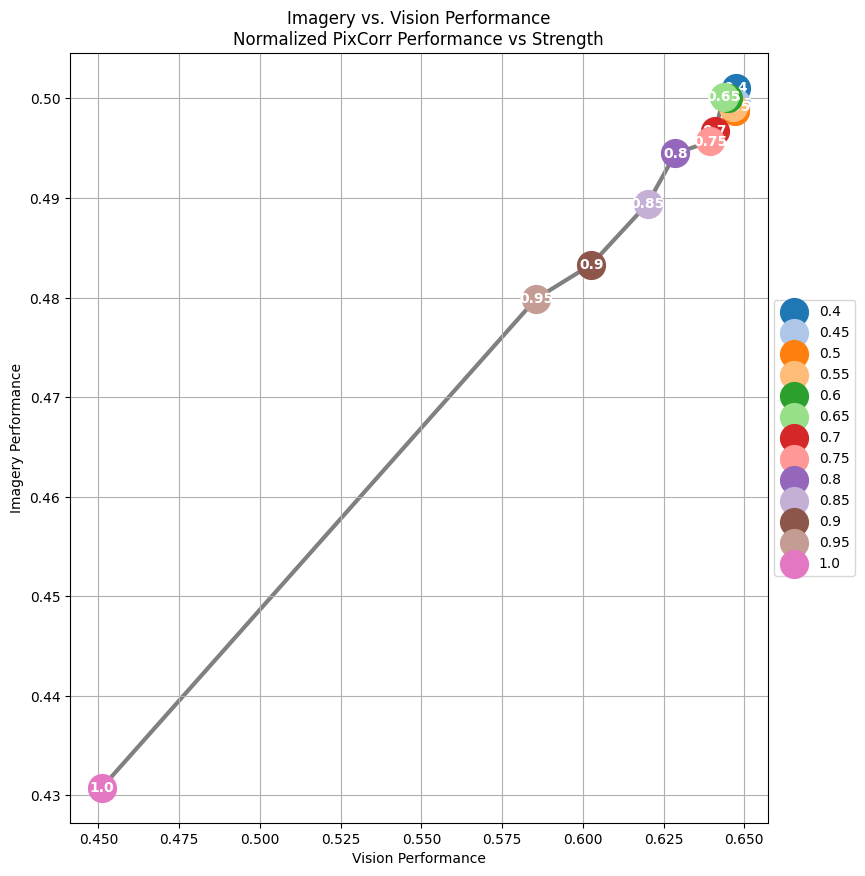

The method with the highest y coordinate for imagery is: 0.65
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized SSIM Performance vs Strength.png


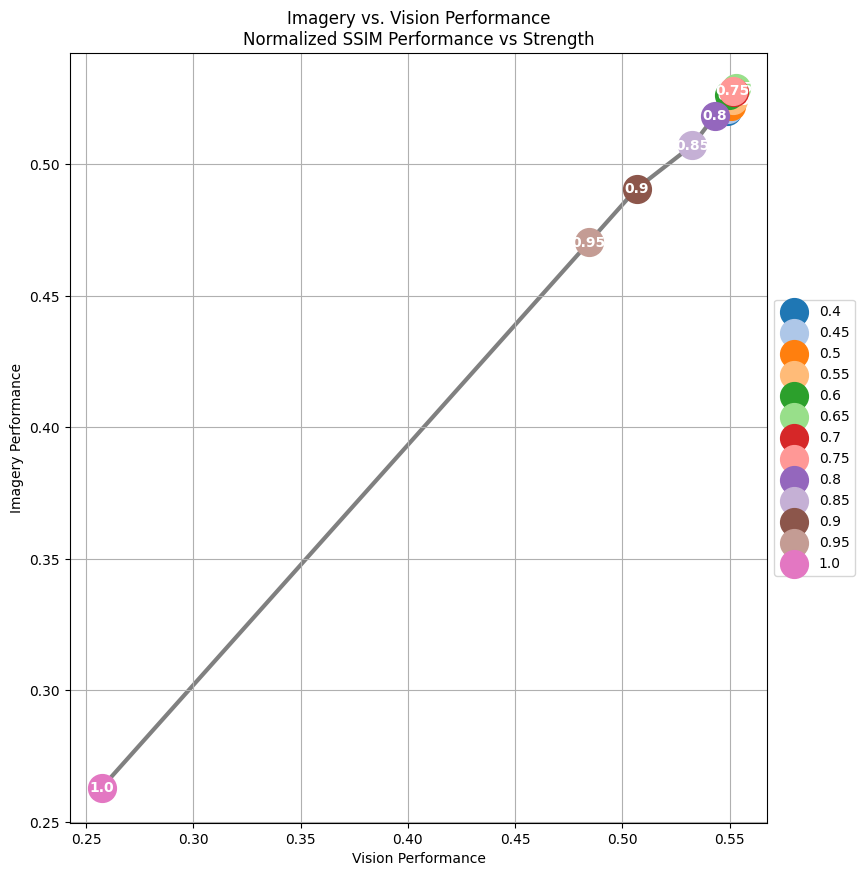

The method with the highest y coordinate for imagery is: 0.45
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized AlexNet(2) Performance vs Strength.png


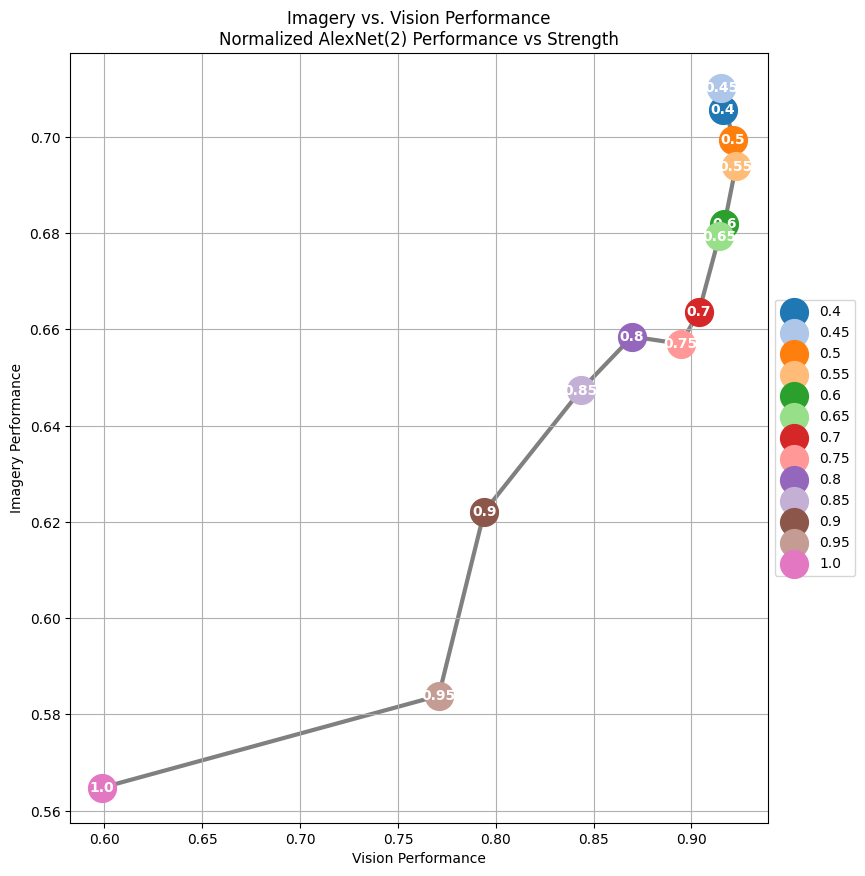

The method with the highest y coordinate for imagery is: 0.4
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized AlexNet(5) Performance vs Strength.png


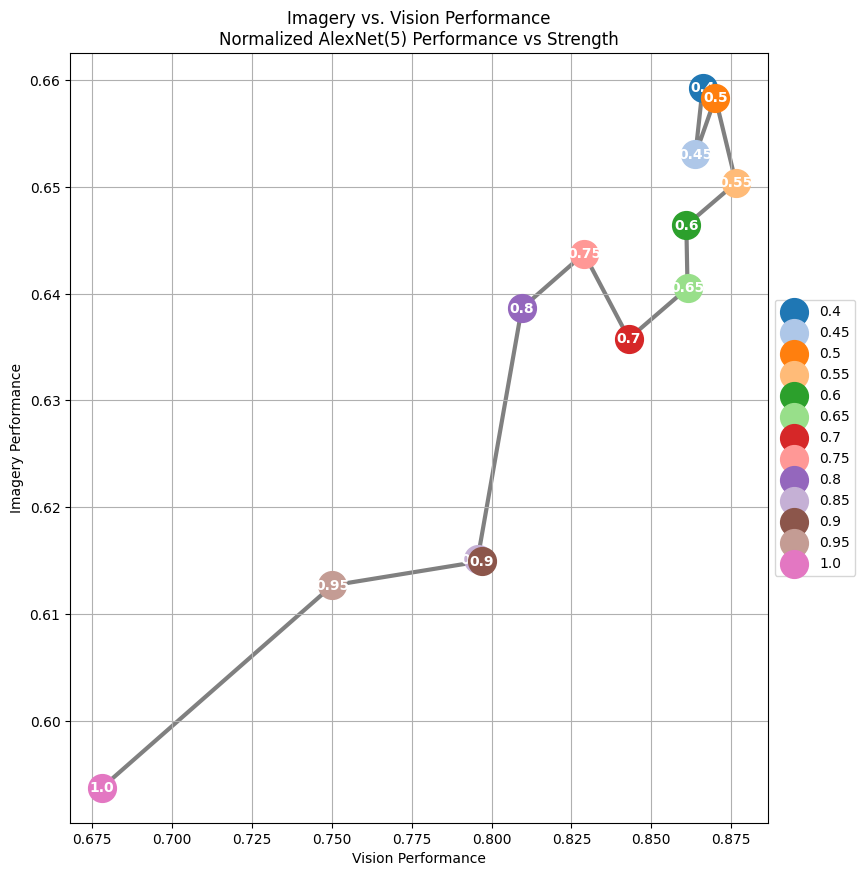

The method with the highest y coordinate for imagery is: 0.4
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized InceptionV3 Performance vs Strength.png


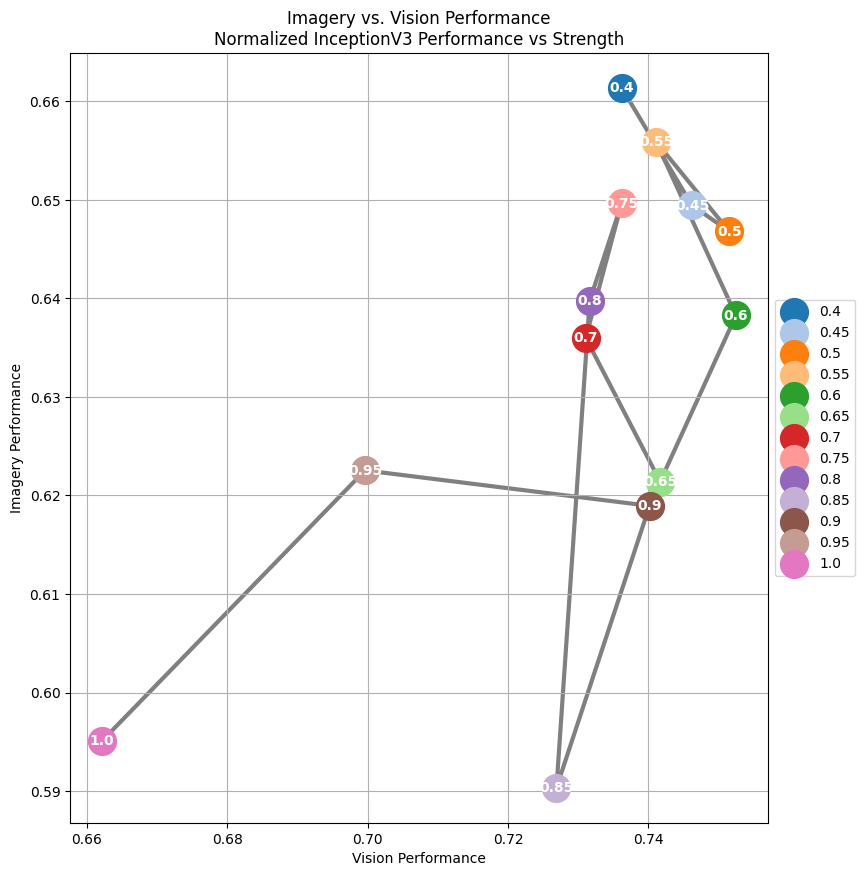

The method with the highest y coordinate for imagery is: 1.0
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized CLIP Performance vs Strength.png


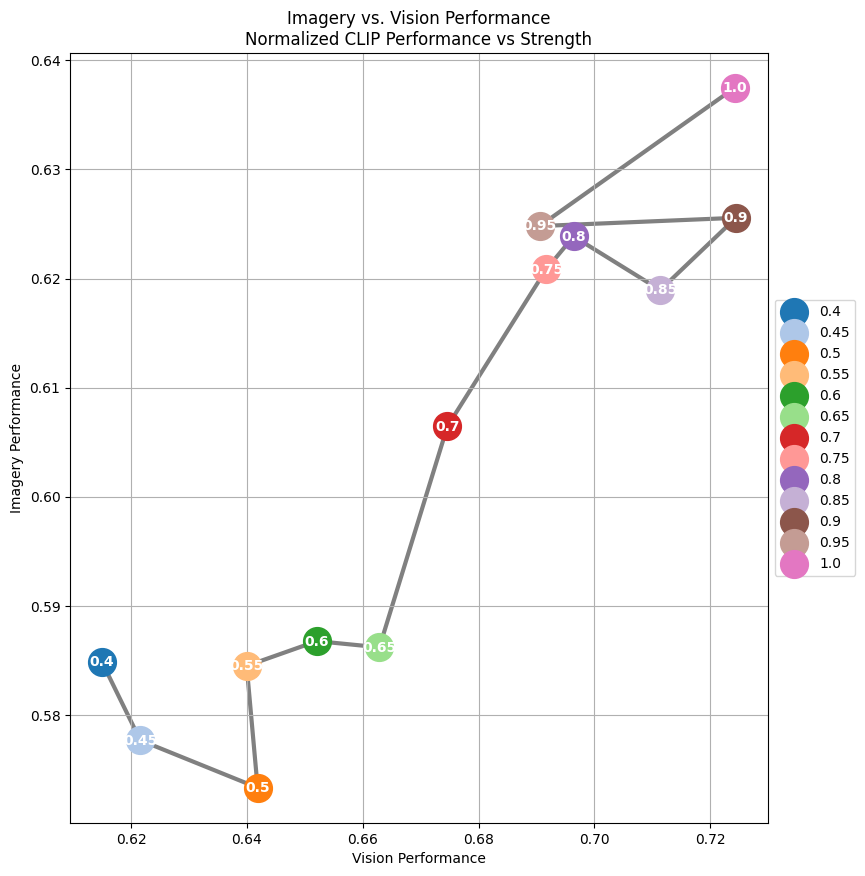

The method with the highest y coordinate for imagery is: 0.8
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized EffNet-B Performance vs Strength.png


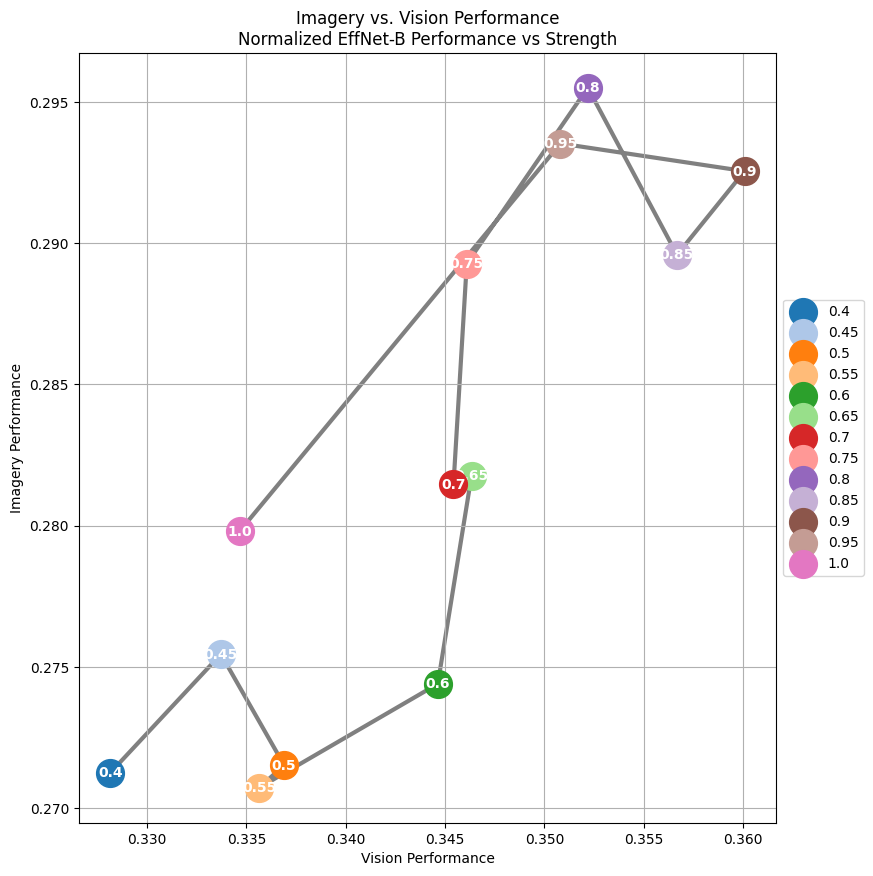

The method with the highest y coordinate for imagery is: 0.4
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized SwAV Performance vs Strength.png


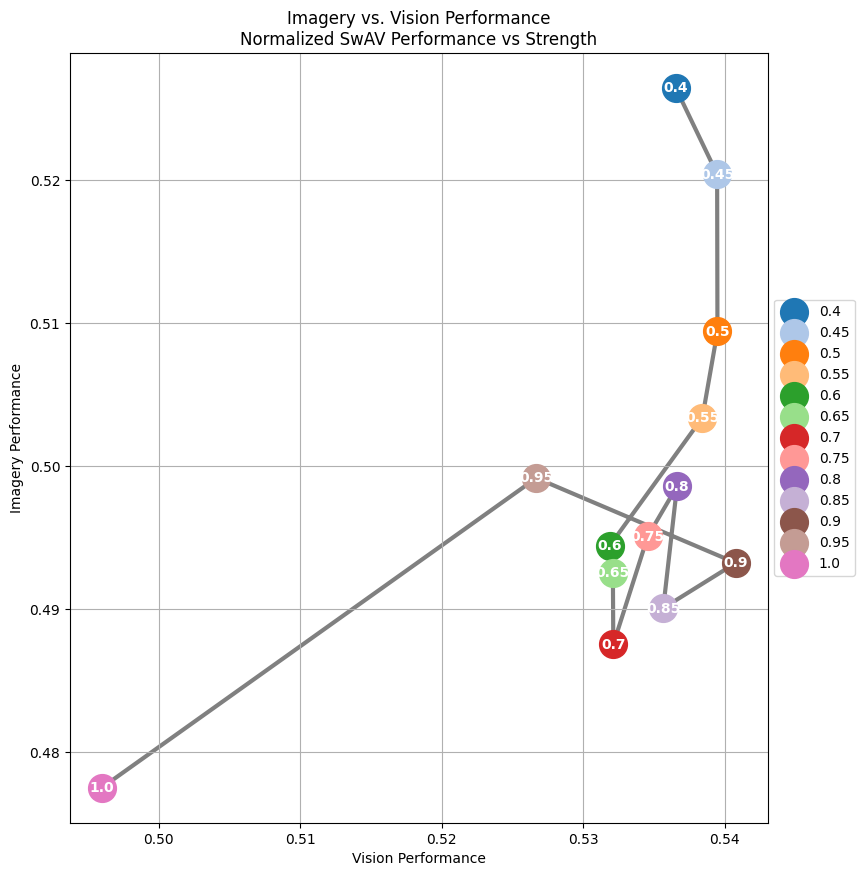

The method with the highest y coordinate for imagery is: 0.4
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized Brain Corr. nsd_general Performance vs Strength.png


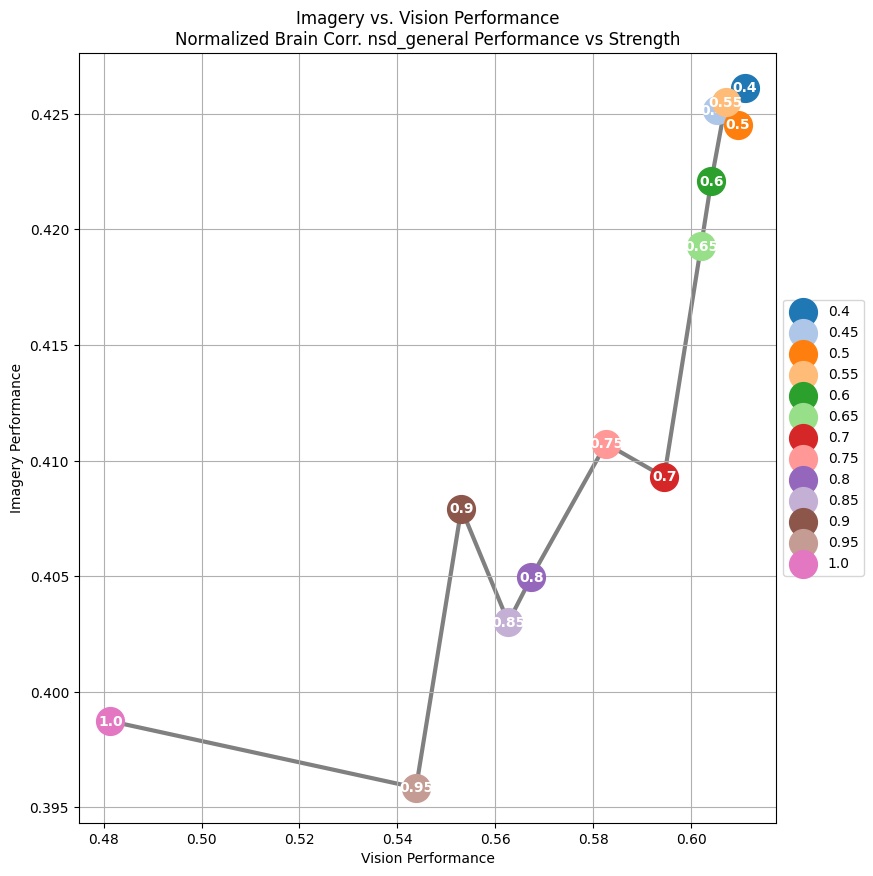

The method with the highest y coordinate for imagery is: 0.4
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized Brain Corr. EVC Performance vs Strength.png


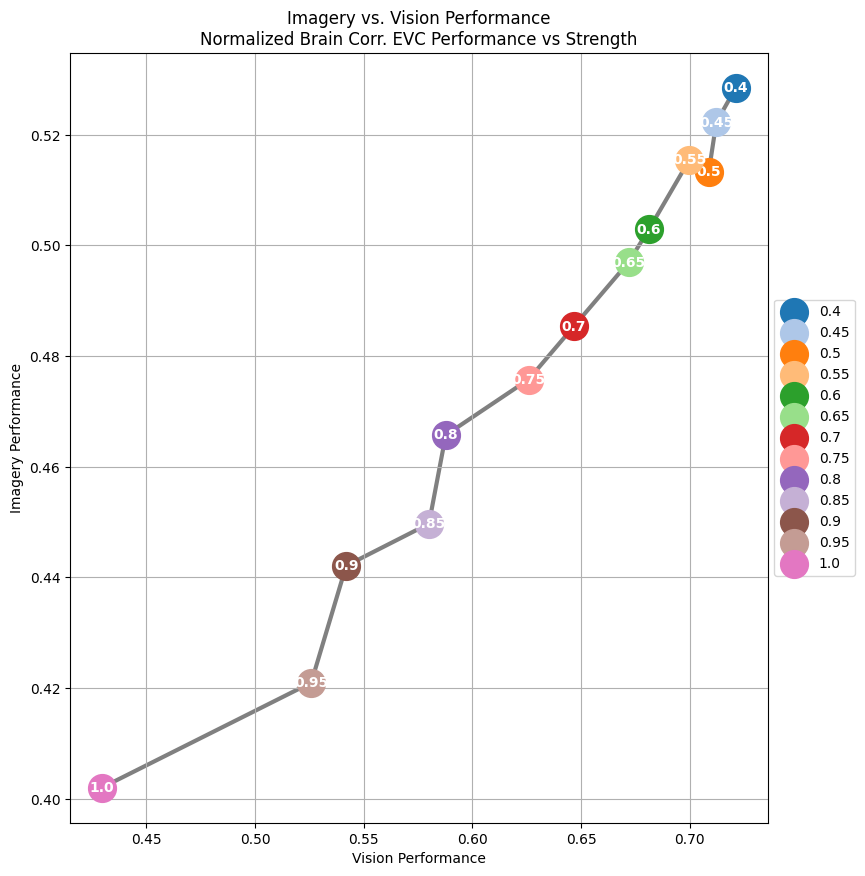

The method with the highest y coordinate for imagery is: 0.9
Saving scatter plot to /home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/Normalized Brain Corr. higher_vis Performance vs Strength.png


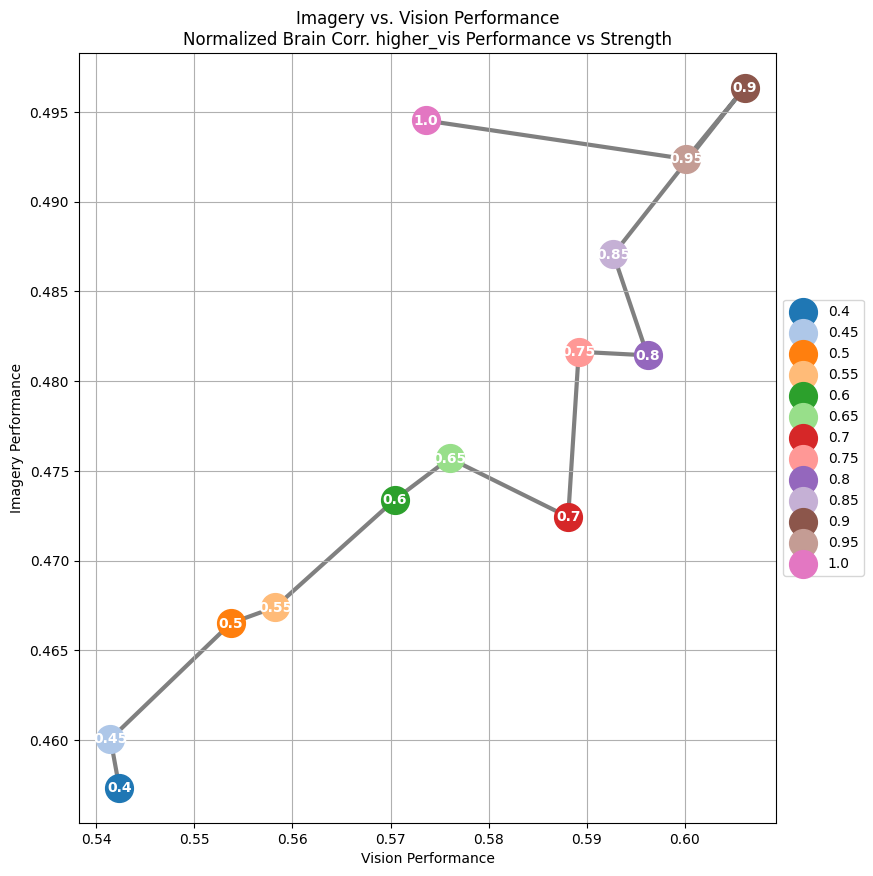

In [39]:
output_path = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/figures/"

criteria = [
    "PixCorr",
    "SSIM",
    "AlexNet(2)",
    "AlexNet(5)",
    "InceptionV3",
    "CLIP",
    "EffNet-B",
    "SwAV",
    "Brain Corr. nsd_general",
    "Brain Corr. EVC",
    "Brain Corr. higher_vis",
]
for criterion in criteria:
    criteria = [criterion]
    output_file = f"Normalized {criterion} Performance vs Strength"
    all_metrics = df
    scaler = MinMaxScaler()
    all_metrics[criteria] = scaler.fit_transform(all_metrics[criteria])
    method_mode_scores = all_metrics.groupby(['strength', 'mode'])[criteria].mean()
    method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
    average_scores = method_mode_scores['average_score'].unstack()
    # Plot scatter plot
    plt.figure(figsize=(15, 10))
    ax = plt.subplot(111)

    colors = plt.cm.tab10.colors if len(average_scores.index) <= 10 else plt.cm.tab20.colors
    x_values = []
    y_values = []
    for i, strength in enumerate(average_scores.index):
        x = average_scores.loc[strength, 'vision']
        y = average_scores.loc[strength, 'imagery']
        x_values.append(x)
        y_values.append(y)
        plt.scatter(x, y, color=colors[i % len(colors)], label=strength, s=400, zorder=5)
        plt.text(x, y, str(strength), fontsize=10, ha='center', va='center', color='white', weight='bold', zorder=5)

    # Draw lines connecting the dots in order
    plt.plot(x_values, y_values, linestyle='-', color='gray', linewidth=3, zorder=1)

    highest_method = average_scores['imagery'].idxmax()
    print(f"The method with the highest y coordinate for imagery is: {highest_method}")

    plt.xlabel('Vision Performance')
    plt.ylabel('Imagery Performance')
    plt.title(f'Imagery vs. Vision Performance\n{output_file}')
    box = ax.get_position()
    ax.set_position([box.x0 - 0.06, box.y0, box.width * 0.6, box.height])
    # Put a legend to the right of the current axis
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    # plt.tight_layout()
    output_file = os.path.join(output_path, f'{output_file}.png')
    print(f"Saving scatter plot to {output_file}")
    plt.savefig(output_file, dpi=300)
    plt.show()


# RDM Analysis

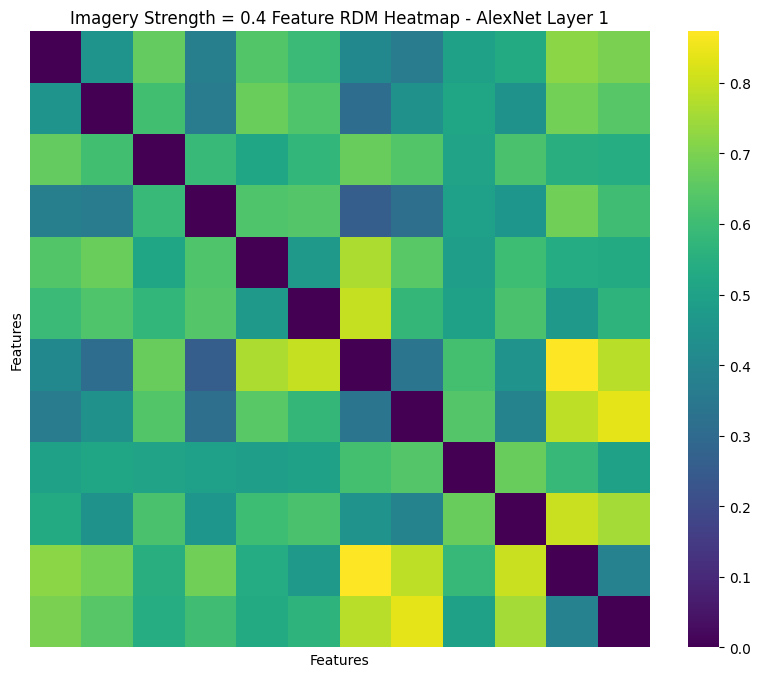

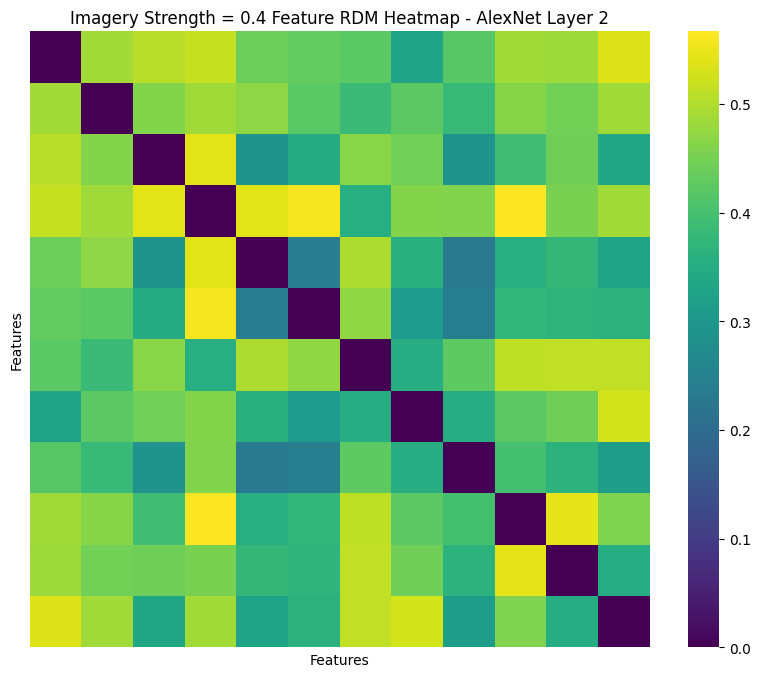

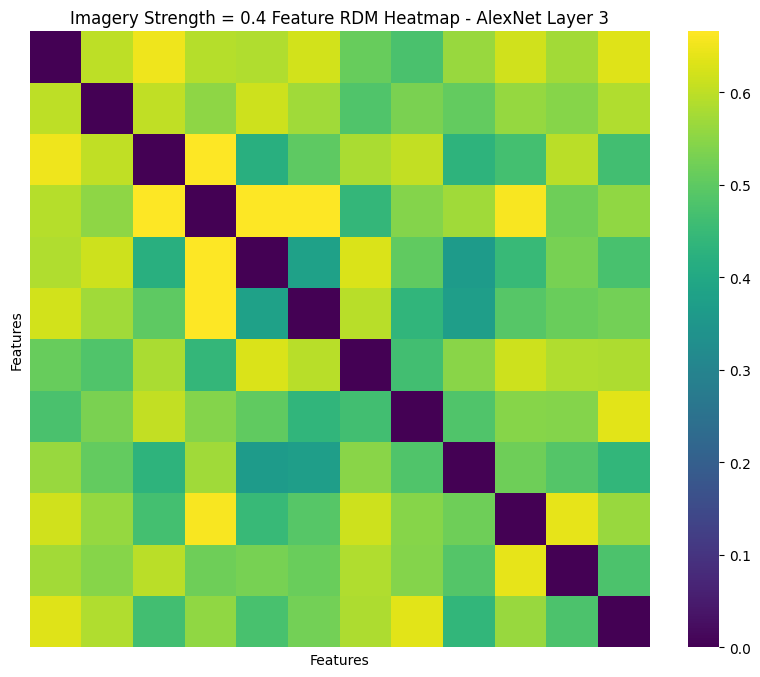

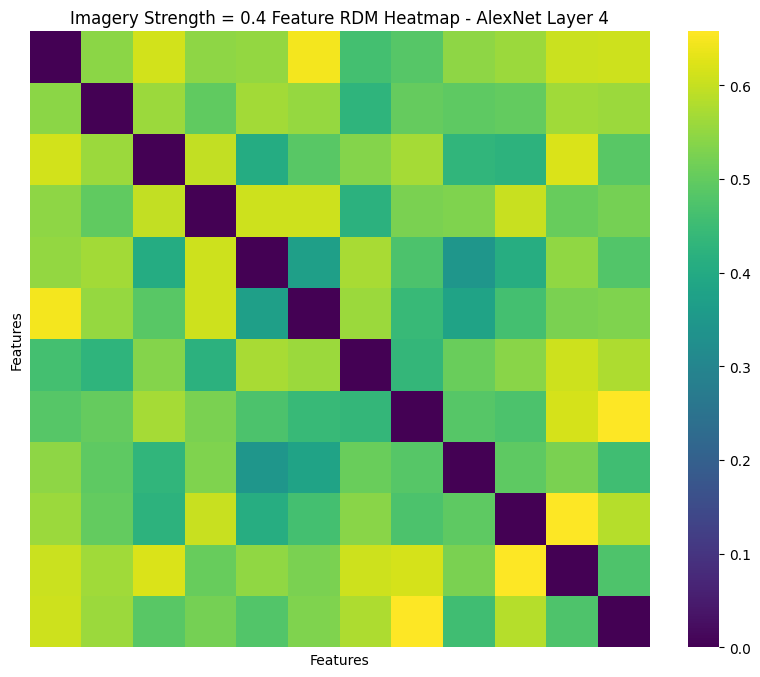

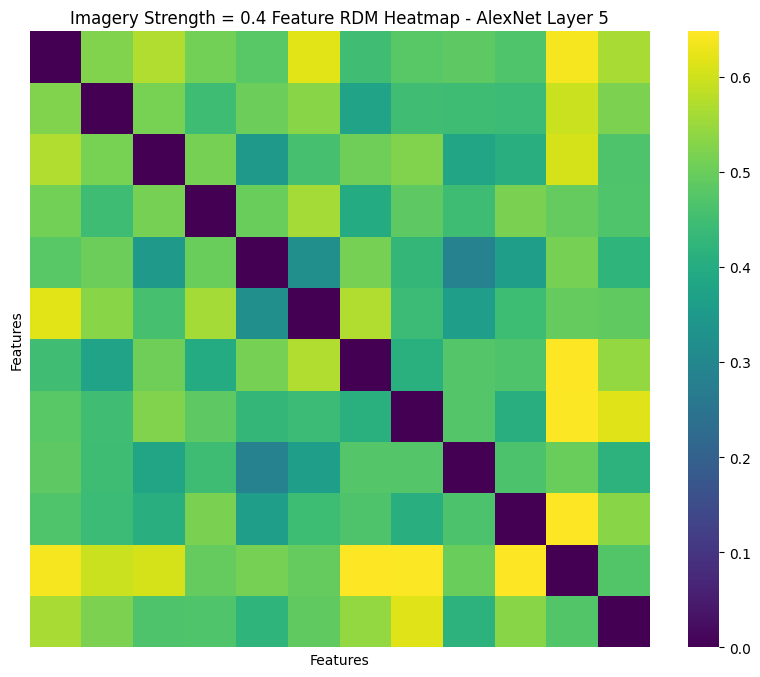

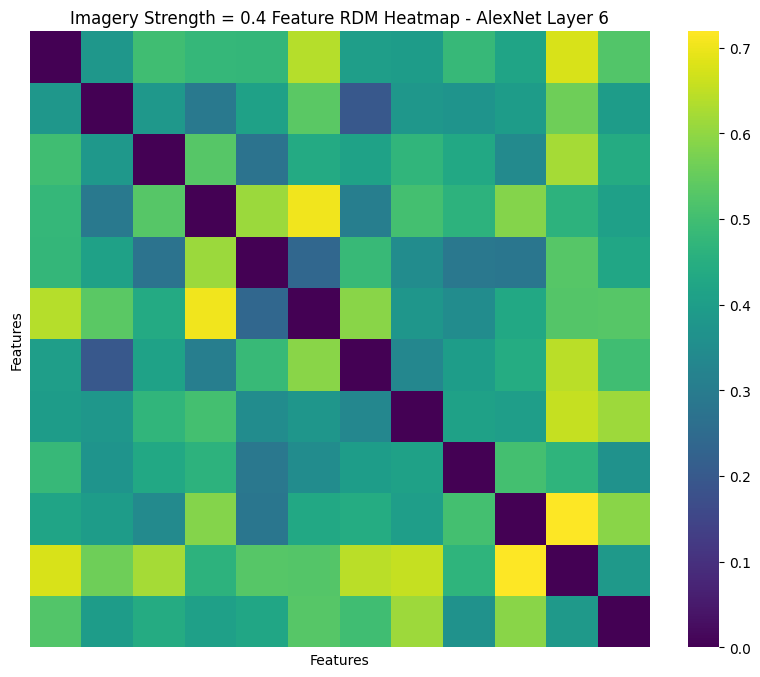

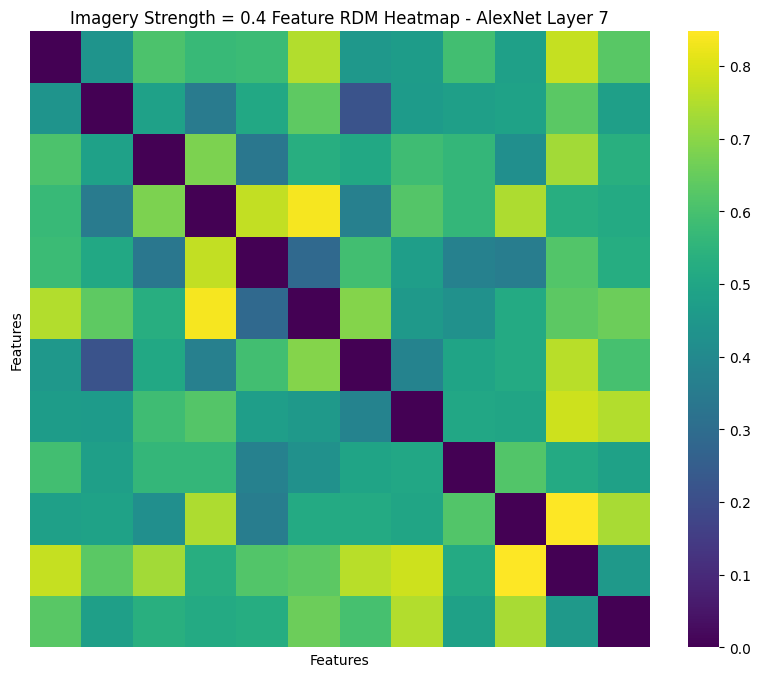

In [6]:
feature_root = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/features/"
mode ='imagery'
strength = 0.4
for alexnet_layer in range(1,8):
    features = []
    for subject in [1, 2, 5, 7]:
        for rep in range(10):
            features.append(np.load(f"{feature_root}/braindiffuser_jp_ts1_subj0{subject}_{strength}_all_recons_{mode}_{rep}_alexnet{alexnet_layer}.npy"))
    features = np.mean(np.stack(features), axis=0)
    feature_rdm = 1 - np.corrcoef(features)
    plt.figure(figsize=(10, 8))
    sns.heatmap(feature_rdm, cmap='viridis', xticklabels=False, yticklabels=False)
    plt.title(f'Imagery Strength = 0.4 Feature RDM Heatmap - AlexNet Layer {alexnet_layer}')
    plt.xlabel('Features')
    plt.ylabel('Features')
    plt.show()

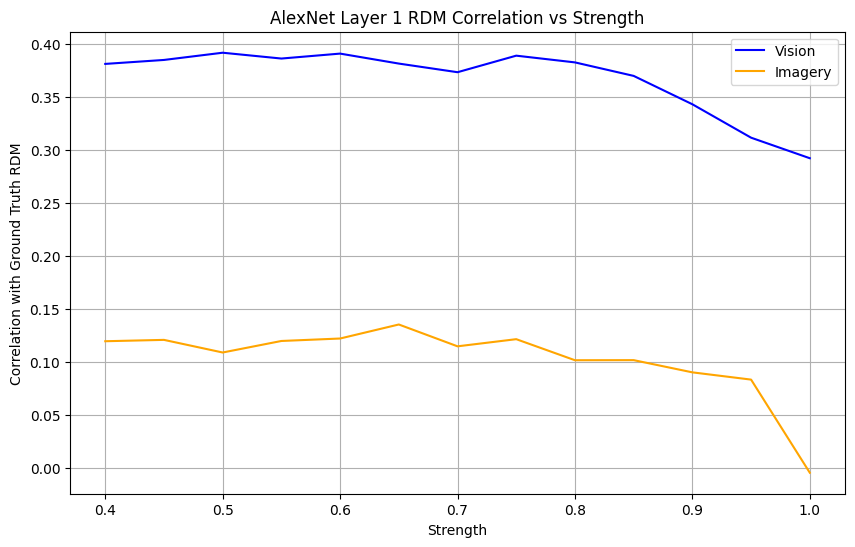

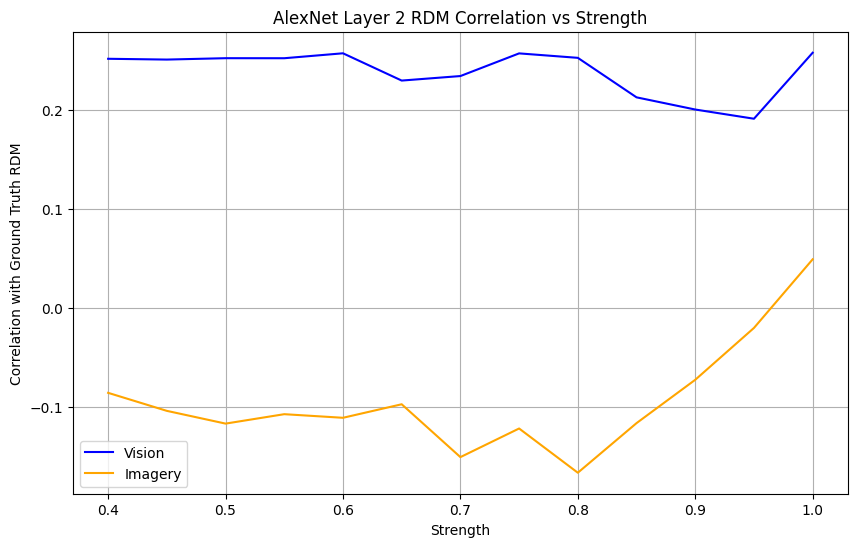

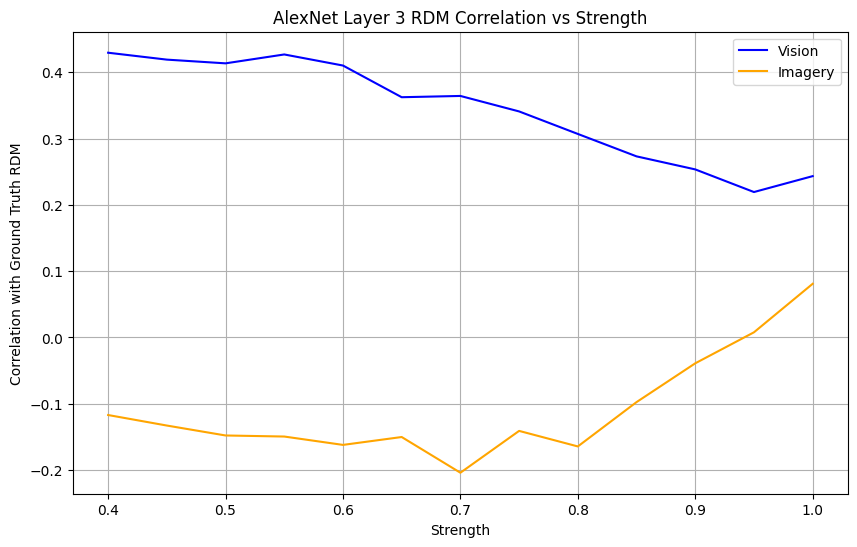

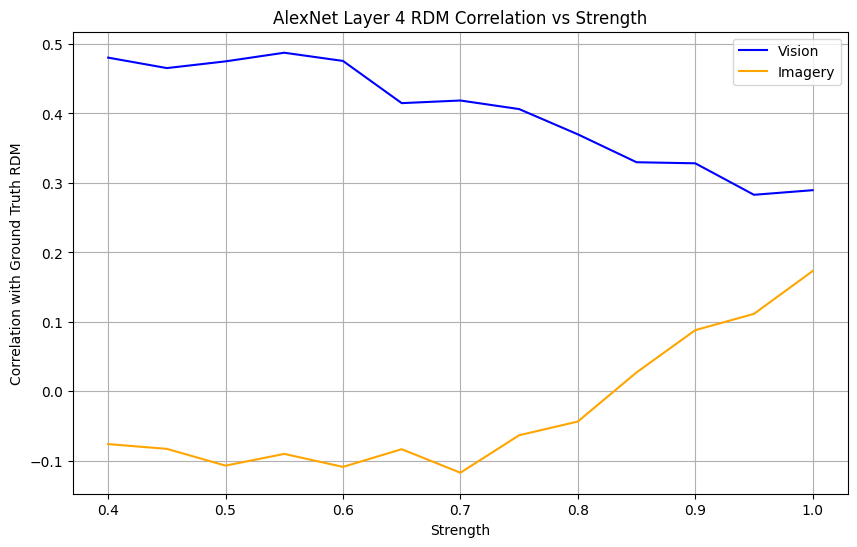

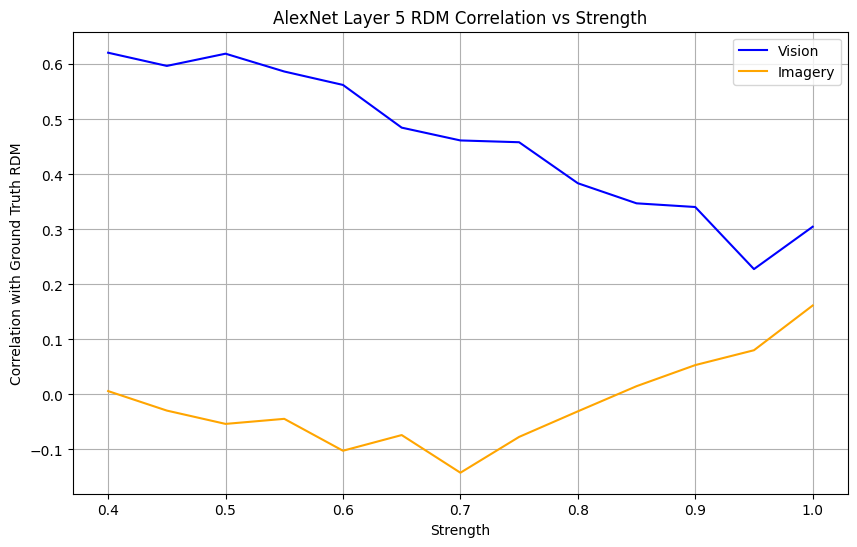

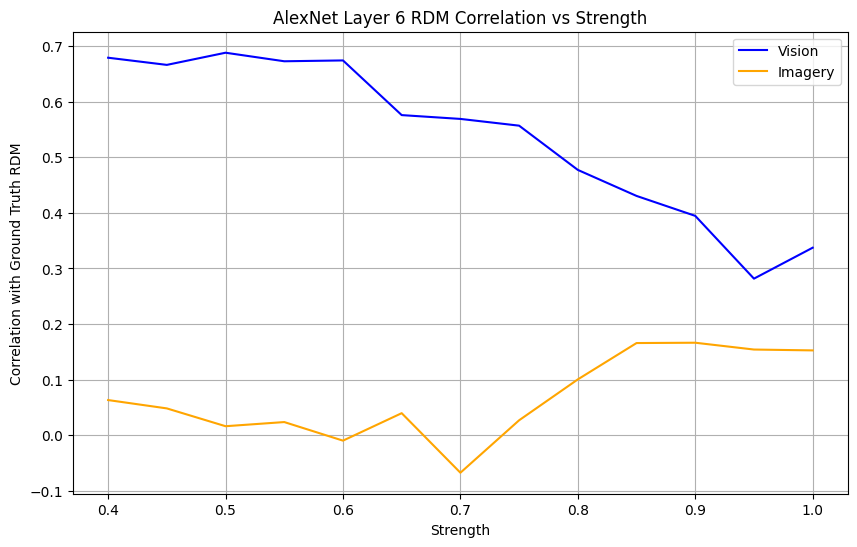

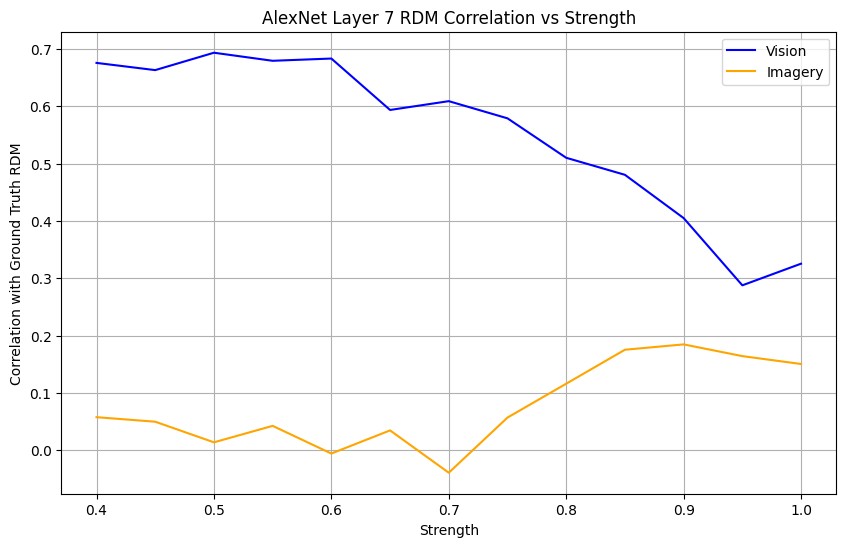

In [47]:
feature_root = "/home/naxos2-raid25/kneel027/home/kneel027/nsd_imagery_journal_paper/features/"
strengths = [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]
for alexnet_layer in range(1, 8):
    gt_features = np.load(f"{feature_root}/alexnet{alexnet_layer}_gt.npy")
    gt_rdm = 1 - np.corrcoef(gt_features)
    triu_indices = np.triu_indices_from(gt_rdm, k=1)
    gt_rdm_upper = gt_rdm[triu_indices]
    
    correlations = {'vision': [], 'imagery': []}
    
    for mode in ['vision', 'imagery']:
        for strength in strengths:
            features = []
            for subject in [1, 2, 5, 7]:
                for rep in range(10):
                    features.append(np.load(f"{feature_root}/braindiffuser_jp_ts1_subj0{subject}_{strength}_all_recons_{mode}_{rep}_alexnet{alexnet_layer}.npy"))
            features = np.mean(np.stack(features), axis=0)
            feature_rdm = 1 - np.corrcoef(features)
            feature_rdm_upper = feature_rdm[triu_indices]
            correlation = pearsonr(gt_rdm_upper, feature_rdm_upper)[0]
            correlations[mode].append(correlation)
    
    plt.figure(figsize=(10, 6))
    plt.plot(strengths, correlations['vision'], label='Vision', color='blue')
    plt.plot(strengths, correlations['imagery'], label='Imagery', color='orange')
    plt.xlabel('Strength')
    plt.ylabel('Correlation with Ground Truth RDM')
    plt.title(f'AlexNet Layer {alexnet_layer} RDM Correlation vs Strength')
    plt.legend()
    plt.grid(True)
    plt.show()
